# Step 6. Machine Learning Models
## K-Means Clustering + K-Nearest Neighbors

**Основной алгоритм:** поиск соседей по 18 игровым признакам, затем бюджет/возраст/исключение референса и TOP-5. KNN реализован как `NearestNeighbors`, не как классификатор или регрессия цены. Разметка для этого поиска не требуется.

**K-Means:** назначает алгоритмическую группу игрового профиля. По желанию поиск ограничивается кластером референса. Ограничение **выключено по умолчанию**: EDA обнаружил слабое разделение групп. При недостатке кандидатов ограниченный режим возвращает меньше пяти или пустой список; скрытого перехода в другие кластеры нет.

Реализация: [src/models.py](../src/models.py). Используется тот же eligibility-фильтр, что и в [baseline](../src/baseline.py). Все fit — только на train; query/test только transform/predict. Цена, возраст, overall и potential не входят в координаты KNN или K-Means.

**Качественная проверка:** математический oracle KNN, одинаковые candidate IDs у ML/baseline, train/test-разделение, устойчивость кластеров при повторном fit всей обработки, чувствительность рекомендаций к шуму рейтингов, leave-one-block-out диагностика, сохранение/загрузка, модульные граничные тесты.

Данные исторические: **26.09.2022**. Test уже исследовался в EDA — это воспроизводимый диагностический benchmark, не новый нетронутый финальный тест. Успех трансфера и рыночная недооценённость здесь не доказываются.


In [1]:
from pathlib import Path
import os
os.environ["LOKY_MAX_CPU_COUNT"]="1"
import hashlib
import json
import sys
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from threadpoolctl import threadpool_limits
%matplotlib inline

_limits=threadpool_limits(1)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"config/feature_set_v1.json").exists())
sys.path.insert(0,str(ROOT))
from src.models import PlayerModels, CORE_FEATURES, FEATURE_GROUPS, eligible_ids_hash
from src.baseline import build_eligible_pool, select_baseline
CORE=list(CORE_FEATURES)
FEATURE_DIR=ROOT/"data/processed/features"
OUT=ROOT/"data/processed/models"
REPORT=ROOT/"reports/models"
OUT.mkdir(parents=True,exist_ok=True);REPORT.mkdir(parents=True,exist_ok=True)
SEED=42
N_INIT=20
REFERENCE_ID="182521"  # T. Kroos; external test profile, older than candidate age ceiling
BUDGET=15_000_000
MAX_AGE=30.0
TOP_K=5
BOOTSTRAPS=1000
REPEATS=20
plt.rcParams.update({"font.family":"DejaVu Sans","figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False})
pd.set_option("display.max_columns",35)
figures=[]

def sha(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def show(fig,name):
    for extension in ["png","svg"]:
        path=REPORT/f"{name}.{extension}";fig.savefig(path,dpi=170,bbox_inches="tight",facecolor="white")
        if extension=="svg":path.write_text("\n".join(s.rstrip() for s in path.read_text(encoding="utf-8").splitlines())+"\n",encoding="utf-8")
    figures.append(name);plt.show();plt.close(fig)

fm=json.loads((FEATURE_DIR/"feature_manifest.json").read_text(encoding="utf-8"))
for filename,meta in fm["outputs"].items():assert sha(FEATURE_DIR/filename)==meta["sha256"]
data=pd.read_csv(FEATURE_DIR/"moneyball_features_2022-09-26.csv",dtype={"fifa_id":str,"tm_id":str,"league_id":str})
train=data.loc[data.split.eq("train")].sort_values("fifa_id").reset_index(drop=True)
test=data.loc[data.split.eq("test")].sort_values("fifa_id").reset_index(drop=True)
assert set(train.fifa_id).isdisjoint(test.fifa_id)
assert data.fifa_id.is_unique and data.as_of_date.eq(fm["cutoff"]).all()
assert data.market_value_date.le(fm["cutoff"]).all()
print("Train:",len(train),"; query/test:",len(test),"; features:",len(CORE),"; sklearn:",sklearn.__version__)


Train: 2308 ; query/test: 578 ; features: 18 ; sklearn: 1.7.2


### 1. Геометрия и выбор K-Means на train

StandardScaler fit только на train. Для KNN применяются веса семи блоков v1: после стандартизации каждый признак умножается на `sqrt(1/(7 × число_признаков_блока))`. Расстояние — cosine; дополнительно выводится RMS различий исходных z-score для контроля различий уровня.

Основной K-Means использует **относительный профиль**: из каждого z-вектора вычитается его среднее, затем применяются веса блоков и L2-нормировка. Это ослабляет общий уровень рейтингов, но не гарантирует независимость от качества игрока. `cluster_mode='weighted'` также поддерживается движком для кластеризации исходных взвешенных z-score.

Число кластеров выбирается из 2…7 только по silhouette на одной фиксированной train-подвыборке. Test, цена и эффективность рекомендаций не участвуют в выборе k. Устойчивость кластера не равна доказательству существования естественной игровой роли.


In [2]:
scaler_probe=StandardScaler().fit(train[CORE].astype(float))
z_probe=scaler_probe.transform(train[CORE].astype(float))
group_of={f:g for g,fs in FEATURE_GROUPS.items() for f in fs}
weights=np.array([np.sqrt(1/(len(FEATURE_GROUPS)*len(FEATURE_GROUPS[group_of[f]]))) for f in CORE])
style_probe=normalize((z_probe-z_probe.mean(axis=1,keepdims=True))*weights)
sample_ids=np.random.default_rng(SEED).choice(len(train),min(1000,len(train)),replace=False)
selection=[]
for k in range(2,8):
    candidate=KMeans(n_clusters=k,n_init=N_INIT,random_state=SEED).fit(style_probe)
    selection.append({"k":k,"train_silhouette":float(silhouette_score(style_probe[sample_ids],candidate.labels_[sample_ids])),
                      "inertia":float(candidate.inertia_)})
selection=pd.DataFrame(selection)
BEST_K=int(selection.sort_values(["train_silhouette","k"],ascending=[False,True]).iloc[0].k)
model=PlayerModels(n_clusters=BEST_K,random_state=SEED,n_init=N_INIT,cluster_mode="relative",cutoff=fm["cutoff"]).fit(train,gallery=train)
assert model.train_ids_==train.fifa_id.tolist()
assert np.allclose(model.scaler_.mean_,train[CORE].mean())
assert np.allclose(model.weights_,weights)
train_clusters=model.predict_clusters(train)
test_clusters=model.predict_clusters(test)
cluster_train=model.cluster_vectors(train)
cluster_test=model.cluster_vectors(test)
cluster_quality={"k":BEST_K,"train_silhouette":float(silhouette_score(cluster_train[sample_ids],train_clusters[sample_ids])),
                 "test_silhouette":float(silhouette_score(cluster_test,test_clusters)),
                 "test_davies_bouldin":float(davies_bouldin_score(cluster_test,test_clusters))}
display(selection);display(pd.DataFrame([cluster_quality]))


,k,train_silhouette,inertia
0,2,0.166861,1899.121989
1,3,0.169609,1609.310129
2,4,0.139110,1494.156919
3,5,0.135193,1412.188582
4,6,0.119016,1354.919733
5,7,0.111986,1311.021428


,k,train_silhouette,test_silhouette,test_davies_bouldin
0,3,0.169609,0.16894,1.775706


### 2. Устойчивость K-Means и интерпретация

В 20 повторах оставляем случайные 80% уникальных train-игроков и заново fit **scaler + K-Means**. Сравниваем назначения всего исходного train через Adjusted Rand Index (ARI). Это устойчивость при фиксированном выбранном k; неопределённость выбора k отдельно не оценивается.

Имена Cluster 0…k−1 условны. Для интерпретации показываются центры по игровым блокам и средний overall. Если группы сохраняют различия общего качества или имеют низкий silhouette, это ограничение кластерного поиска, а не повод присвоить им убедительные названия ролей.


,train,test
0,841,201
1,769,190
2,698,187


,passing,ball_control,mobility,decisions,physical,defending,long_shots
cluster,,,,,,,
0,-0.591,-0.645,0.074,-0.518,0.074,0.047,-0.746
1,0.146,0.394,0.498,0.047,-0.513,-0.672,0.326
2,0.551,0.343,-0.638,0.572,0.476,0.684,0.540


overall      age_at_cutoff     
           mean size          mean size
cluster                                
0         64.22  841         24.63  841
1         68.04  769         25.38  769
2         71.30  698         28.51  698

,k,train_silhouette,test_silhouette,test_davies_bouldin,ari_median,ari_p05,ari_p95
0,3,0.169609,0.16894,1.775706,0.862635,0.752818,0.936128


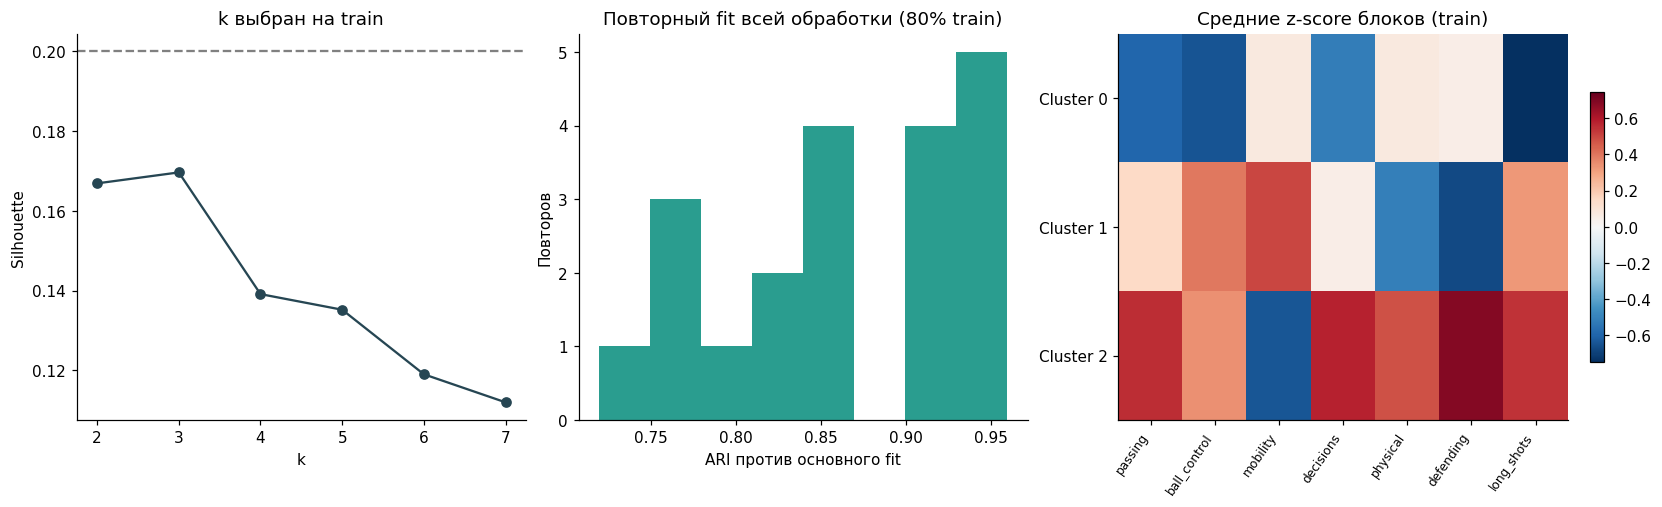

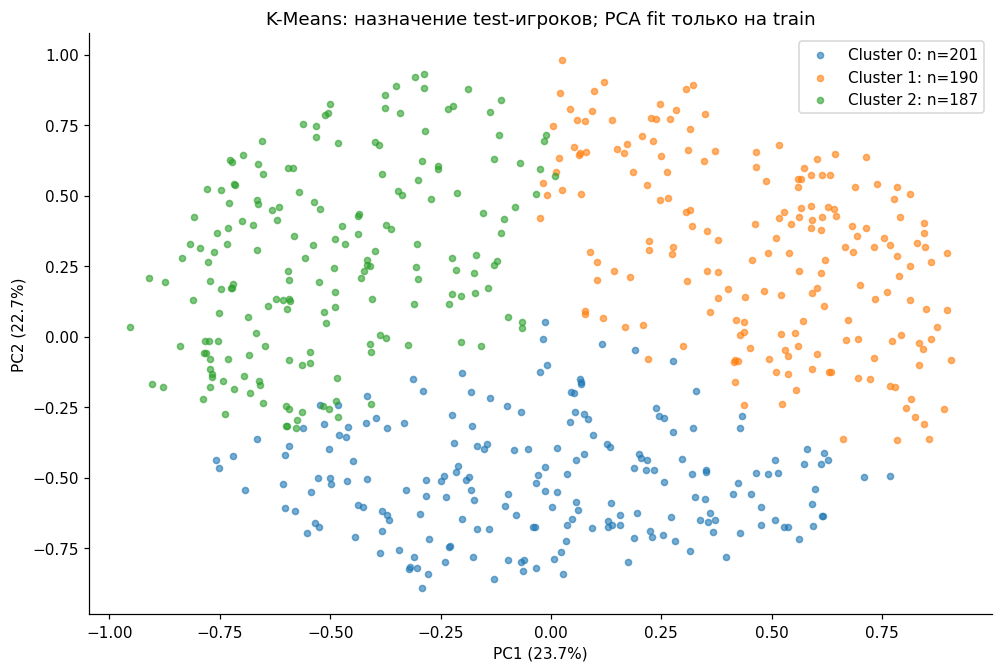

In [3]:
stability=[]
for repeat in range(REPEATS):
    ids=np.random.default_rng(SEED+repeat).choice(len(train),int(.8*len(train)),replace=False)
    refit=PlayerModels(n_clusters=BEST_K,random_state=SEED+repeat+1,n_init=10,cutoff=fm["cutoff"]).fit(train.iloc[ids],gallery=train)
    stability.append(float(adjusted_rand_score(train_clusters,refit.predict_clusters(train))))
cluster_quality.update(ari_median=float(np.median(stability)),ari_p05=float(np.quantile(stability,.05)),ari_p95=float(np.quantile(stability,.95)))
cluster_sizes=pd.DataFrame({"train":pd.Series(train_clusters).value_counts(),"test":pd.Series(test_clusters).value_counts()}).fillna(0).sort_index()
Z_train=model.scaler_.transform(train[CORE].astype(float));Z_test=model.scaler_.transform(test[CORE].astype(float))
W_train=model.transform(train);W_test=model.transform(test)
block_table=pd.DataFrame({g:Z_train[:,[CORE.index(f) for f in fs]].mean(axis=1) for g,fs in FEATURE_GROUPS.items()})
block_table["cluster"]=train_clusters
block_means=block_table.groupby("cluster").mean()
cluster_context=train[["overall","age_at_cutoff"]].assign(cluster=train_clusters).groupby("cluster").agg(["mean","size"])
display(cluster_sizes);display(block_means.round(3));display(cluster_context.round(2));display(pd.DataFrame([cluster_quality]))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
axes[0].plot(selection.k,selection.train_silhouette,"o-",color="#264653")
axes[0].axhline(.20,color="grey",linestyle="--");axes[0].set(title="k выбран на train",xlabel="k",ylabel="Silhouette")
axes[1].hist(stability,bins=8,color="#2a9d8f");axes[1].set(title="Повторный fit всей обработки (80% train)",xlabel="ARI против основного fit",ylabel="Повторов")
im=axes[2].imshow(block_means,cmap="RdBu_r",aspect="auto",vmin=-max(abs(block_means.to_numpy()).max(),.01),vmax=max(abs(block_means.to_numpy()).max(),.01))
axes[2].set_xticks(range(len(FEATURE_GROUPS)),FEATURE_GROUPS,rotation=55,ha="right",fontsize=8)
axes[2].set_yticks(range(BEST_K),[f"Cluster {k}" for k in range(BEST_K)])
axes[2].set_title("Средние z-score блоков (train)");fig.colorbar(im,ax=axes[2],shrink=.7)
show(fig,"01_kmeans_quality")

pca=PCA(n_components=2,random_state=SEED).fit(cluster_train)
projection=pca.transform(cluster_test)
fig,ax=plt.subplots(figsize=(9,6),layout="constrained")
for k in range(BEST_K):
    mask=test_clusters==k;ax.scatter(projection[mask,0],projection[mask,1],s=16,alpha=.6,label=f"Cluster {k}: n={mask.sum()}")
ax.set(title="K-Means: назначение test-игроков; PCA fit только на train",xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.legend();show(fig,"02_kmeans_test_projection")


### 3. KNN: известный референс → все соседи → фильтры → TOP-5

Передать можно ID из каталога или полный профиль внешнего игрока. Демонстрация использует Тони Крооса из test; его самого нет в train-галерее. Возрастной лимит относится к **кандидатам**, поэтому референс может быть старше или дороже бюджета.

Движок получает расстояния до всей галереи, затем применяет тот же historical/CM/budget/age-фильтр, что и baseline, исключает ID референса и берёт TOP-5. Это не теряет доступного шестого соседа, если первые пять оказались слишком дорогими. При равном расстоянии используются меньшая цена и ID. Цена разрешает равенство, но не входит в формулу расстояния.

Сценарий: 15 млн, возраст кандидатов ≤30.0 лет. EUR — ранее зафиксированное допущение единиц TM, а не подтверждённая валюта архива. Рыночная оценка не равна фактической сумме сделки.


In [4]:
reference=data.loc[data.fifa_id.eq(REFERENCE_ID)].iloc[0]
SETTINGS=dict(max_value=BUDGET,max_age=MAX_AGE,top_k=TOP_K)
global_result=model.recommend(reference,**SETTINGS)
cluster_result=model.recommend(reference,within_cluster=True,**SETTINGS)
global_pool=model.eligible_pool(reference,max_value=BUDGET,max_age=MAX_AGE)
cluster_pool=model.eligible_pool(reference,max_value=BUDGET,max_age=MAX_AGE,within_cluster=True)
baseline_global=select_baseline(global_pool,cutoff=fm["cutoff"],excluded_fifa_ids=[REFERENCE_ID],**SETTINGS)
baseline_cluster=select_baseline(cluster_pool,cutoff=fm["cutoff"],excluded_fifa_ids=[REFERENCE_ID],**SETTINGS)
assert global_result.attrs["pool_audit"]["eligible_ids_sha256"]==eligible_ids_hash(global_pool.fifa_id)
assert cluster_result.attrs["pool_audit"]["eligible_ids_sha256"]==eligible_ids_hash(cluster_pool.fifa_id)
display(pd.DataFrame([reference[["fifa_id","short_name","age_at_cutoff","overall","tm_market_value"]]]))
columns=["model_rank","fifa_id","short_name","age_at_cutoff","overall","tm_market_value","similarity","rms_z","cluster","strong_profile_match"]
display(Markdown("**Основной KNN, вся допустимая train-галерея:**"));display(global_result[columns].round(4))
display(Markdown("**KNN только в кластере референса:**"));display(cluster_result[columns].round(4))
display(Markdown("**Контрольный baseline на том же глобальном пуле:**"));display(baseline_global[["baseline_rank","short_name","overall","tm_market_value"]])
print("Global pool:",len(global_pool),"; same-cluster pool:",len(cluster_pool))
display(Markdown(f"**Проверка близости:** {int(global_result.strong_profile_match.sum())}/{len(global_result)} строк TOP-5 одновременно проходят cosine ≥0,90 и RMS ≤0,75. "
                 "Высокое сходство направления может сочетаться с существенной разницей уровня; ближайший игрок не обязательно является полноценной заменой."))


Global pool: 1726 ; same-cluster pool: 378


,fifa_id,short_name,age_at_cutoff,overall,tm_market_value
87,182521,T. Kroos,32.726202,88,20000000.0


**Основной KNN, вся допустимая train-галерея:**

,model_rank,fifa_id,short_name,age_at_cutoff,overall,tm_market_value,similarity,rms_z,cluster,strong_profile_match
0,1,199823,Campaña,29.3230,78,5000000.0,0.9487,1.0422,2,False
1,2,243627,Y. Adli,22.1606,75,9000000.0,0.9370,1.2804,2,False
2,3,253109,J. Veerman,23.8526,78,14000000.0,0.9288,1.0829,2,False
3,4,220854,É. Gutiérrez,27.2832,76,7000000.0,0.9237,1.3077,2,False
4,5,237161,S. Longstaff,24.9067,74,15000000.0,0.9223,1.3283,2,False


**KNN только в кластере референса:**

,model_rank,fifa_id,short_name,age_at_cutoff,overall,tm_market_value,similarity,rms_z,cluster,strong_profile_match
0,1,199823,Campaña,29.3230,78,5000000.0,0.9487,1.0422,2,False
1,2,243627,Y. Adli,22.1606,75,9000000.0,0.9370,1.2804,2,False
2,3,253109,J. Veerman,23.8526,78,14000000.0,0.9288,1.0829,2,False
3,4,220854,É. Gutiérrez,27.2832,76,7000000.0,0.9237,1.3077,2,False
4,5,237161,S. Longstaff,24.9067,74,15000000.0,0.9223,1.3283,2,False


**Контрольный baseline на том же глобальном пуле:**

,baseline_rank,short_name,overall,tm_market_value
0,1,Sergi Darder,82,14000000.0
1,2,E. Can,82,14000000.0
2,3,R. Andrich,81,13000000.0
3,4,K. Demirbay,81,15000000.0
4,5,C. Tolisso,81,15000000.0


**Проверка близости:** 0/5 строк TOP-5 одновременно проходят cosine ≥0,90 и RMS ≤0,75. Высокое сходство направления может сочетаться с существенной разницей уровня; ближайший игрок не обязательно является полноценной заменой.

### 4. Независимый oracle и массовая проверка корректности

Для test-запросов проверяется результат sklearn NearestNeighbors против прямого numpy-расчёта cosine по стандартизированным векторам. При математически равных расстояниях допустим любой эквивалентный набор на границе TOP-k; отдельно проверяется расстояние k-го соседа.

Это проверка реализации точного поиска, **не accuracy футбольного прогноза**. Здесь нет размеченных истинных «лучших трансферов».


In [5]:
all_knn,global_audit=model.recommend_many(test,**SETTINGS)
all_cluster,cluster_audit=model.recommend_many(test,within_cluster=True,**SETTINGS)
candidate_index={pid:i for i,pid in enumerate(train.fifa_id)}
query_index={pid:i for i,pid in enumerate(test.fifa_id)}
oracle_rows=[]
normalized_gallery=normalize(W_train)
probe_ids=np.random.default_rng(SEED).choice(len(test),min(40,len(test)),replace=False)
for i in probe_ids:
    reference_id=test.iloc[i].fifa_id
    manual_distance=1-normalize(W_test[i:i+1])[0]@normalized_gallery.T
    available=global_pool[["fifa_id","tm_market_value"]].copy()
    # For disjoint test/train, the global eligible pool is identical for every query.
    available["distance"]=[manual_distance[candidate_index[pid]] for pid in available.fifa_id]
    exact=available.sort_values(["distance","tm_market_value","fifa_id"]).head(TOP_K)
    got=all_knn.loc[all_knn.reference_id.eq(reference_id)]
    got_distance=np.array([manual_distance[candidate_index[pid]] for pid in got.fifa_id])
    valid=(len(got)==len(exact) and np.allclose(np.sort(got_distance),np.sort(exact.distance),atol=1e-10))
    oracle_rows.append({"reference_id":reference_id,"correct_distances_tie_aware":bool(valid),
                        "same_ids":set(got.fifa_id)==set(exact.fifa_id)})
oracle=pd.DataFrame(oracle_rows)
assert oracle.correct_distances_tie_aware.all()
assert all_knn.tm_market_value.le(BUDGET).all() and all_knn.age_at_cutoff.le(MAX_AGE).all()
assert not all_knn.fifa_id.eq(all_knn.reference_id).any()
assert not all_cluster.fifa_id.eq(all_cluster.reference_id).any() and all_cluster.same_cluster.all()
assert not all_knn.duplicated(["reference_id","fifa_id"]).any()
assert all_knn.market_value_date.le(fm["cutoff"]).all()
assert global_audit.eligible_ids_sha256.eq(eligible_ids_hash(global_pool.fifa_id)).all()
display(oracle);print("Oracle-correct queries:",int(oracle.correct_distances_tie_aware.sum()),"/",len(oracle))


Oracle-correct queries: 40 / 40


,reference_id,correct_distances_tie_aware,same_ids
0,258632,True,True
1,194669,True,True
2,263333,True,True
3,206562,True,True
4,191053,True,True
5,263918,True,True
6,266392,True,True
7,194761,True,True
8,232826,True,True
9,245850,True,True


### 5. Сравнение с baseline на строго одинаковых кандидатах

Сравниваются четыре режима: baseline_global / knn_global и baseline_cluster / knn_cluster. Во второй паре **оба** метода ограничены тем же кластером. Кластерный baseline — контроль эффекта фильтра, а не замена исходного global baseline.

Показываются заполнение TOP-5, cosine, RMS, overall и записанная стоимость. Cosine и RMS используют те же входы, что KNN, поэтому преимущество по ним ожидаемо и **не является независимым доказательством спортивного качества**. Все показатели отдельно приводятся для дорогих test-игроков со стоимостью >15 млн.


,method,references,fill_fraction,mean_cosine,mean_rms_z,mean_overall,mean_value,strong_match_fraction,cohort
0,baseline_cluster,578,1.0,0.2018,1.4455,78.8706,1.097336e+07,0.0311,all_test
1,baseline_global,578,1.0,0.0453,1.7728,81.4000,1.420000e+07,0.0270,all_test
2,knn_cluster,578,1.0,0.8433,0.6302,67.5824,2.912587e+06,0.2391,all_test
3,knn_global,578,1.0,0.8490,0.6209,67.5931,2.948945e+06,0.2540,all_test
4,baseline_cluster,41,1.0,0.8204,0.9343,80.1561,1.264634e+07,0.2244,expensive_test
5,baseline_global,41,1.0,0.8188,0.9791,81.4000,1.420000e+07,0.2146,expensive_test
6,knn_cluster,41,1.0,0.9303,0.6711,76.0732,7.611951e+06,0.5805,expensive_test
7,knn_global,41,1.0,0.9337,0.6616,76.1951,7.827561e+06,0.6000,expensive_test


,mean,conditional_95_ci,interpretation
0,0.803687,"[0.7561267641264697, 0.8526437671880551]","same-feature descriptive metric, not independe..."


,references,mean,conditional_95_ci
0,41,0.114931,"[0.08208529184647496, 0.1511265780525218]"


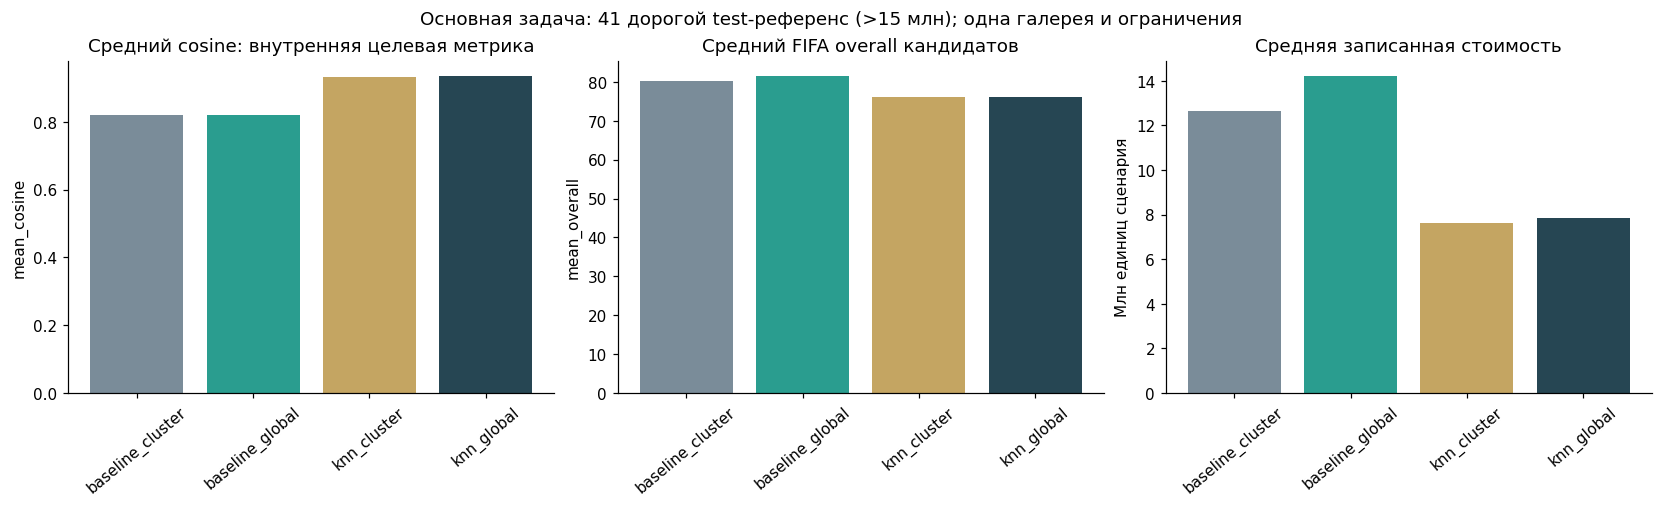

In [6]:
gallery_labels=dict(zip(model.gallery_.fifa_id,model.gallery_clusters_))
base_templates={"global":baseline_global}
cluster_pools={}
for k in range(BEST_K):
    subgroup=global_pool.loc[global_pool.fifa_id.map(gallery_labels).eq(k)].copy()
    cluster_pools[k]=subgroup
    base_templates[k]=select_baseline(subgroup,cutoff=fm["cutoff"],**SETTINGS)

def annotate_baseline(frame,ref_id,i):
    result=frame.copy()
    positions=np.array([candidate_index[pid] for pid in result.fifa_id],dtype=int)
    a=W_test[i];b=W_train[positions]
    result["similarity"]=(b@a)/(np.linalg.norm(b,axis=1)*np.linalg.norm(a))
    result["rms_z"]=np.sqrt(np.mean((Z_train[positions]-Z_test[i])**2,axis=1))
    result["reference_id"]=ref_id
    return result

quality_rows=[];baseline_parts=[]
global_groups={key:part for key,part in all_knn.groupby("reference_id")}
cluster_groups={key:part for key,part in all_cluster.groupby("reference_id")}
for i,row in test.iterrows():
    cluster=int(test_clusters[i]);ref_id=row.fifa_id
    assert cluster_audit.loc[cluster_audit.reference_id.eq(ref_id),"eligible_ids_sha256"].iloc[0]==eligible_ids_hash(cluster_pools[cluster].fifa_id)
    bg=annotate_baseline(base_templates["global"],ref_id,i)
    bc=annotate_baseline(base_templates[cluster],ref_id,i)
    for name,part in [("baseline_global",bg),("knn_global",global_groups.get(ref_id,all_knn.iloc[:0])),
                      ("baseline_cluster",bc),("knn_cluster",cluster_groups.get(ref_id,all_cluster.iloc[:0]))]:
        if name.startswith("baseline"):baseline_parts.append(part.assign(method=name))
        quality_rows.append({"reference_id":ref_id,"method":name,"expensive_reference":bool(row.tm_market_value>BUDGET),
                             "returned":len(part),"fill_fraction":len(part)/TOP_K,
                             "mean_cosine":float(part.similarity.mean()) if len(part) else np.nan,
                             "mean_rms_z":float(part.rms_z.mean()) if len(part) else np.nan,
                             "mean_overall":float(part.overall.mean()) if len(part) else np.nan,
                             "mean_value":float(part.tm_market_value.mean()) if len(part) else np.nan,
                             "strong_match_fraction":float((part.similarity.ge(.9)&part.rms_z.le(.75)).mean()) if len(part) else np.nan})
quality=pd.DataFrame(quality_rows)
summary_parts=[]
for cohort,frame in [("all_test",quality),("expensive_test",quality.loc[quality.expensive_reference])]:
    summary_parts.append(frame.groupby("method").agg(references=("reference_id","size"),fill_fraction=("fill_fraction","mean"),
       mean_cosine=("mean_cosine","mean"),mean_rms_z=("mean_rms_z","mean"),mean_overall=("mean_overall","mean"),
       mean_value=("mean_value","mean"),strong_match_fraction=("strong_match_fraction","mean")).reset_index().assign(cohort=cohort))
quality_summary=pd.concat(summary_parts,ignore_index=True)
display(quality_summary.round(4))
wide=quality.pivot(index="reference_id",columns="method",values="mean_cosine")
paired=wide.knn_global-wide.baseline_global
samples=np.random.default_rng(SEED).integers(0,len(paired),size=(BOOTSTRAPS,len(paired)))
internal_cosine_gain={"mean":float(paired.mean()),"conditional_95_ci":np.quantile(paired.to_numpy()[samples].mean(axis=1),[.025,.975]).tolist(),
                      "interpretation":"same-feature descriptive metric, not independent transfer quality"}
display(pd.DataFrame([internal_cosine_gain]))
expensive_ids=set(test.loc[test.tm_market_value.gt(BUDGET),"fifa_id"])
expensive_paired=paired.loc[paired.index.isin(expensive_ids)]
expensive_boot=np.random.default_rng(SEED).integers(0,len(expensive_paired),size=(BOOTSTRAPS,len(expensive_paired)))
expensive_cosine_gain={"references":len(expensive_paired),"mean":float(expensive_paired.mean()),
                       "conditional_95_ci":np.quantile(expensive_paired.to_numpy()[expensive_boot].mean(axis=1),[.025,.975]).tolist()}
display(pd.DataFrame([expensive_cosine_gain]))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
overall=quality_summary.loc[quality_summary.cohort.eq("expensive_test")]
fig.suptitle(f"Основная задача: {len(expensive_ids)} дорогой test-референс (>15 млн); одна галерея и ограничения")
for ax,metric,title in [(axes[0],"mean_cosine","Средний cosine: внутренняя целевая метрика"),(axes[1],"mean_overall","Средний FIFA overall кандидатов"),(axes[2],"mean_value","Средняя записанная стоимость")]:
    values=overall[metric]/1e6 if metric=="mean_value" else overall[metric]
    ax.bar(overall.method,values,color=["#7a8c99","#2a9d8f","#c4a562","#264653"])
    ax.set_title(title);ax.tick_params(axis="x",rotation=40)
    ax.set_ylabel("Млн единиц сценария" if metric=="mean_value" else metric)
show(fig,"03_same_pool_baseline_comparison")


### 6. Проверка со скрытым блоком игровых признаков

Для каждого из 7 блоков **полностью исключаем его признаки** из поиска. По остальным блокам fit scaler на train и выбираем соседей в том же допустимом пуле. Скрытые атрибуты используются только для оценки: сравниваем профиль референса со средним профилем TOP-5 кандидатов по RMS скрытых train-z-score.

Это дополнительная проверка восстановления игровой структуры, которую алгоритм непосредственно не оптимизировал. Это отдельный диагностический эксперимент с уменьшенным набором признаков, не перенастройка основного движка и не доказательство реальной результативности. Рейтинги FIFA коррелируют между собой; независимых будущих футбольных результатов здесь нет.


,knn_hidden_rms,baseline_hidden_rms,improvement
hidden_block,,,
ball_control,0.5057,1.8435,1.3378
decisions,0.5510,1.7455,1.1945
defending,0.5736,1.5899,1.0164
long_shots,0.5813,1.8317,1.2504
mobility,0.7930,1.0240,0.2310
passing,0.5379,2.0172,1.4793
physical,0.7162,1.3772,0.6610


,mean_rms_improvement,paired_reference_bootstrap_95,positive_improvement_blocks,total_blocks
0,1.024334,"[0.974416225746865, 1.0761543347350075]",7,7


,knn_hidden_rms,baseline_hidden_rms,improvement
hidden_block,,,
ball_control,0.6818,0.5790,-0.1028
decisions,0.6801,0.5419,-0.1382
defending,0.5144,0.5812,0.0668
long_shots,0.5370,0.8428,0.3058
mobility,0.8188,0.9714,0.1525
passing,0.7820,0.7084,-0.0737
physical,0.6447,0.8076,0.1629


,references,mean_rms_improvement,paired_reference_bootstrap_95,positive_improvement_blocks,total_blocks
0,41,0.053334,"[-0.037731875668287965, 0.1481234583929585]",4,7


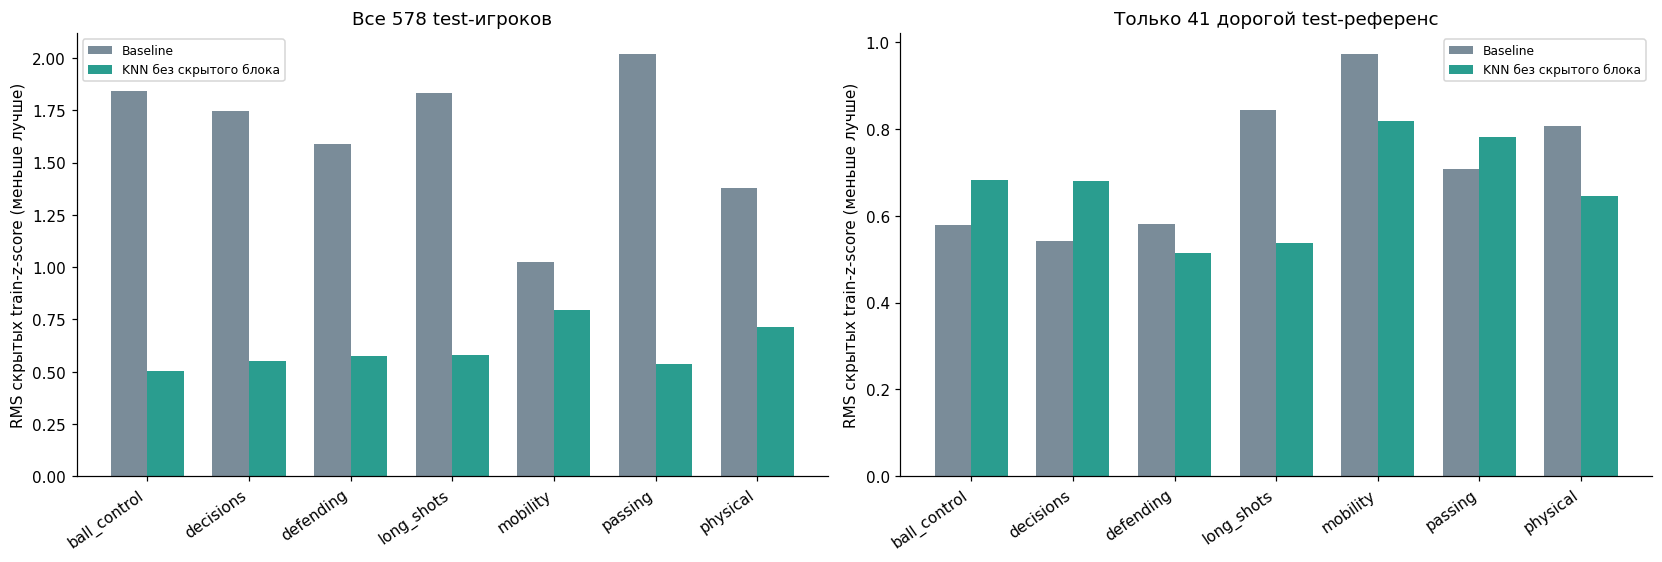

In [7]:
allowed_positions=np.array([candidate_index[pid] for pid in global_pool.fifa_id],dtype=int)
lobo_rows=[]
baseline_positions=np.array([candidate_index[pid] for pid in baseline_global.fifa_id],dtype=int)
for block,hidden in FEATURE_GROUPS.items():
    retained=[f for f in CORE if f not in hidden]
    scaler=StandardScaler().fit(train[retained].astype(float))
    g=scaler.transform(train[retained].astype(float));q=scaler.transform(test[retained].astype(float))
    remaining_groups={name:[f for f in fs if f in retained] for name,fs in FEATURE_GROUPS.items()}
    remaining_groups={name:fs for name,fs in remaining_groups.items() if fs}
    w=np.array([np.sqrt(1/(len(remaining_groups)*len(remaining_groups[group_of[f]]))) for f in retained])
    search=NearestNeighbors(metric="cosine",algorithm="brute",n_jobs=1).fit(g*w)
    distances,positions=search.kneighbors(q*w,n_neighbors=len(train))
    hidden_ids=[CORE.index(f) for f in hidden]
    for i,row in test.iterrows():
        d=np.empty(len(train));d[positions[i]]=distances[i]
        order=np.lexsort((train.iloc[allowed_positions].fifa_id.to_numpy(dtype=str),train.iloc[allowed_positions].tm_market_value.to_numpy(float),d[allowed_positions]))
        chosen=allowed_positions[order[:TOP_K]]
        target=Z_test[i,hidden_ids]
        knn_error=float(np.sqrt(np.mean((Z_train[chosen][:,hidden_ids].mean(axis=0)-target)**2)))
        base_error=float(np.sqrt(np.mean((Z_train[baseline_positions][:,hidden_ids].mean(axis=0)-target)**2)))
        lobo_rows.append({"reference_id":row.fifa_id,"hidden_block":block,"retrieval_features":len(retained),
                          "knn_hidden_rms":knn_error,"baseline_hidden_rms":base_error,"improvement":base_error-knn_error})
lobo=pd.DataFrame(lobo_rows)
lobo_summary=lobo.groupby("hidden_block")[["knn_hidden_rms","baseline_hidden_rms","improvement"]].mean()
per_reference=lobo.groupby("reference_id").improvement.mean()
boot_ids=np.random.default_rng(SEED).integers(0,len(per_reference),size=(BOOTSTRAPS,len(per_reference)))
lobo_result={"mean_rms_improvement":float(per_reference.mean()),"paired_reference_bootstrap_95":np.quantile(per_reference.to_numpy()[boot_ids].mean(axis=1),[.025,.975]).tolist(),
             "positive_improvement_blocks":int(lobo_summary.improvement.gt(0).sum()),"total_blocks":len(FEATURE_GROUPS)}
display(lobo_summary.round(4));display(pd.DataFrame([lobo_result]))
expensive_lobo=lobo.loc[lobo.reference_id.isin(expensive_ids)]
lobo_expensive_summary=expensive_lobo.groupby("hidden_block")[["knn_hidden_rms","baseline_hidden_rms","improvement"]].mean()
expensive_improvement=expensive_lobo.groupby("reference_id").improvement.mean()
exp_boot=np.random.default_rng(SEED).integers(0,len(expensive_improvement),size=(BOOTSTRAPS,len(expensive_improvement)))
lobo_expensive_result={"references":len(expensive_improvement),"mean_rms_improvement":float(expensive_improvement.mean()),
    "paired_reference_bootstrap_95":np.quantile(expensive_improvement.to_numpy()[exp_boot].mean(axis=1),[.025,.975]).tolist(),
    "positive_improvement_blocks":int(lobo_expensive_summary.improvement.gt(0).sum()),"total_blocks":len(FEATURE_GROUPS)}
display(lobo_expensive_summary.round(4));display(pd.DataFrame([lobo_expensive_result]))
fig,axes=plt.subplots(1,2,figsize=(15,5),layout="constrained")
for ax,table,title in [(axes[0],lobo_summary,f"Все {len(test)} test-игроков"),(axes[1],lobo_expensive_summary,f"Только {len(expensive_ids)} дорогой test-референс")]:
    x=np.arange(len(table))
    ax.bar(x-.18,table.baseline_hidden_rms,width=.36,label="Baseline",color="#7a8c99")
    ax.bar(x+.18,table.knn_hidden_rms,width=.36,label="KNN без скрытого блока",color="#2a9d8f")
    ax.set_xticks(x,table.index,rotation=35,ha="right");ax.set(title=title,ylabel="RMS скрытых train-z-score (меньше лучше)")
    ax.legend(fontsize=8)
show(fig,"04_hidden_block_validation")


### 7. Устойчивость рекомендаций к небольшому шуму

Берём фиксированные 50 test-референсов, 10 раз добавляем независимый Gaussian-шум σ=1 рейтинговый пункт к 18 входам, ограничивая значения шкалой 1…99. Scaler, кластеры и галерея не переобучаются. Измеряем overlap@5 исходного и изменённого списка и частоту изменения кластера референса.

Нестабильность около границ соседства или кластеров — реальное ограничение, а не техническая ошибка. Дорогие/молодые игроки не заменяют игровые признаки при ранжировании.


,references,repeats,noise_sigma_rating,mean_overlap_at5,mean_cluster_overlap_at5,cluster_change_fraction
0,50,10,1.0,0.7976,0.8128,0.014


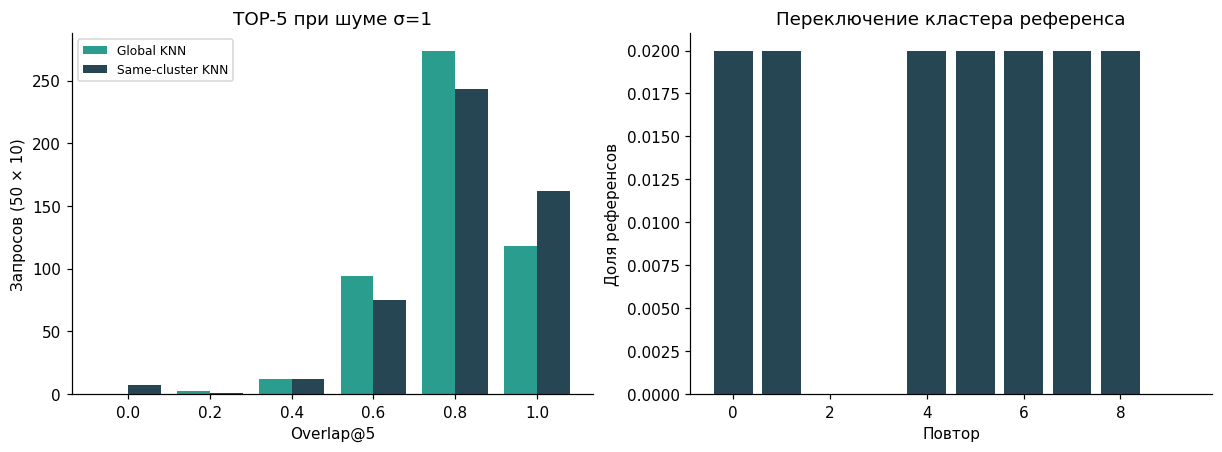

In [8]:
sample=test.iloc[np.random.default_rng(SEED).choice(len(test),min(50,len(test)),replace=False)].copy()
base_rank, _=model.recommend_many(sample,**SETTINGS)
base_sets={pid:set(part.fifa_id) for pid,part in base_rank.groupby("reference_id")}
base_cluster_sets={pid:set(part.fifa_id) for pid,part in all_cluster.groupby("reference_id") if pid in set(sample.fifa_id)}
base_clusters=dict(zip(sample.fifa_id,model.predict_clusters(sample)))
mean_before=model.scaler_.mean_.copy();centers_before=model.kmeans_.cluster_centers_.copy()
robustness=[]
for repeat in range(10):
    noisy=sample.copy()
    changed=np.clip(noisy[CORE].to_numpy(float)+np.random.default_rng(SEED+repeat).normal(0,1,size=(len(noisy),len(CORE))),1,99)
    for j,column in enumerate(CORE):noisy[column]=changed[:,j]
    ranks,_=model.recommend_many(noisy,**SETTINGS)
    cluster_ranks,_=model.recommend_many(noisy,within_cluster=True,**SETTINGS)
    clusters=model.predict_clusters(noisy)
    sets={pid:set(part.fifa_id) for pid,part in ranks.groupby("reference_id")}
    cluster_sets={pid:set(part.fifa_id) for pid,part in cluster_ranks.groupby("reference_id")}
    for i,pid in enumerate(noisy.fifa_id):
        original=base_sets.get(pid,set());current=sets.get(pid,set())
        overlap=len(original&current)/len(original) if original else np.nan
        original_cluster=base_cluster_sets.get(pid,set());current_cluster=cluster_sets.get(pid,set())
        cluster_overlap=len(original_cluster&current_cluster)/len(original_cluster) if original_cluster else np.nan
        robustness.append({"reference_id":pid,"repeat":repeat,"overlap_at5":overlap,"cluster_overlap_at5":cluster_overlap,"cluster_changed":int(clusters[i])!=base_clusters[pid]})
robustness=pd.DataFrame(robustness)
assert np.array_equal(mean_before,model.scaler_.mean_) and np.array_equal(centers_before,model.kmeans_.cluster_centers_)
robustness_summary={"references":len(sample),"repeats":10,"noise_sigma_rating":1.,
                    "mean_overlap_at5":float(robustness.overlap_at5.mean()),"mean_cluster_overlap_at5":float(robustness.cluster_overlap_at5.mean()),"cluster_change_fraction":float(robustness.cluster_changed.mean())}
display(pd.DataFrame([robustness_summary]))
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
axes[0].hist([robustness.overlap_at5,robustness.cluster_overlap_at5],bins=np.linspace(-.1,1.1,7),color=["#2a9d8f","#264653"],label=["Global KNN","Same-cluster KNN"])
axes[0].legend(fontsize=8)
axes[0].set(title="TOP-5 при шуме σ=1",xlabel="Overlap@5",ylabel="Запросов (50 × 10)")
changes=robustness.groupby("repeat").cluster_changed.mean()
axes[1].bar(changes.index,changes,color="#264653")
axes[1].set(title="Переключение кластера референса",xlabel="Повтор",ylabel="Доля референсов")
show(fig,"05_noise_robustness")


### 8. Сохранение модели и итоговые гарантии

Сохраняем обученный bundle с scaler, весами, K-Means, NearestNeighbors и галереей; SHA-256, версии и параметры — в JSON. Проверяем рекомендации и кластерные назначения после загрузки собственного артефакта. Параметры fit не меняются при запросах.

Модульные тесты: независимый oracle, отсутствие self-match, недорогой сосед после дорогих, пустой/малый пул, будущая оценка, строгий кластерный режим, отсутствующие/нечисловые/бесконечные признаки, неоднозначные ID, неподходящие позиции и даты, нулевой вектор, неверные параметры, batch/single parity, перестановка индексов и persistence.

Низкий silhouette означает, что кластеры не следует считать жёсткими доказанными ролями. Основной KNN использует глобальный допустимый пул. `strong_profile_match` — прозрачный описательный флаг cosine ≥0,90 и RMS ≤0,75; отсутствие флага не превращается в обещание хорошего аналога. Similarity не является вероятностью успеха.


In [9]:
bundle=OUT/"player_models_2022-09-26.joblib"
joblib.dump(model,bundle)
restored=joblib.load(bundle)
reloaded=restored.recommend(reference,**SETTINGS)
assert reloaded.fifa_id.tolist()==global_result.fifa_id.tolist()
assert np.allclose(reloaded.similarity,global_result.similarity)
assert np.array_equal(restored.predict_clusters(test),test_clusters)
assert np.array_equal(restored.scaler_.mean_,model.scaler_.mean_)

checks={
 "fit_train_only":int(model.scaler_.n_samples_seen_)==len(train) and set(model.train_ids_).isdisjoint(test.fifa_id),
 "gallery_train_only":set(model.gallery_.fifa_id)==set(train.fifa_id),
 "features_exactly_18_playing":list(model.feature_names_in_)==CORE and len(CORE)==18,
 "no_economic_features_in_geometry":not set(CORE)&{"tm_market_value","age_at_cutoff","overall","potential"},
 "oracle_correct_all_probes":oracle.correct_distances_tie_aware.all(),
 "no_self_match":not all_knn.fifa_id.eq(all_knn.reference_id).any() and not all_cluster.fifa_id.eq(all_cluster.reference_id).any(),
 "budget_respected":all_knn.tm_market_value.le(BUDGET).all() and all_cluster.tm_market_value.le(BUDGET).all(),
 "age_respected":all_knn.age_at_cutoff.le(MAX_AGE).all() and all_cluster.age_at_cutoff.le(MAX_AGE).all(),
 "no_future_values":all_knn.market_value_date.le(fm["cutoff"]).all() and all_cluster.market_value_date.le(fm["cutoff"]).all(),
 "cluster_constraint_respected":all_cluster.same_cluster.all(),
 "same_global_pool_as_baseline":global_audit.eligible_ids_sha256.eq(eligible_ids_hash(global_pool.fifa_id)).all(),
 "topk_no_hidden_fallback":global_audit.returned.eq(np.minimum(global_audit.eligible_count,TOP_K)).all() and cluster_audit.returned.eq(np.minimum(cluster_audit.eligible_count,TOP_K)).all(),
 "queries_do_not_refit":np.array_equal(mean_before,model.scaler_.mean_) and np.array_equal(centers_before,model.kmeans_.cluster_centers_),
 "roundtrip_same_recommendations":reloaded.fifa_id.tolist()==global_result.fifa_id.tolist(),
 "finite_distances":np.isfinite(all_knn[["cosine_distance","similarity","rms_z"]]).all().all(),
 "all_query_ids_evaluated":global_audit.reference_id.nunique()==len(test) and quality.reference_id.nunique()==len(test),
 "hidden_block_diagnostic_complete":len(lobo)==len(test)*len(FEATURE_GROUPS),
}
assert all(checks.values()),{k:v for k,v in checks.items() if not v}
display(pd.DataFrame({"check":checks.keys(),"passed":checks.values()}))

all_knn.to_csv(OUT/"knn_global_recommendations.csv",index=False)
all_cluster.to_csv(OUT/"knn_cluster_recommendations.csv",index=False)
pd.concat(baseline_parts,ignore_index=True).to_csv(OUT/"same_pool_baseline_recommendations.csv",index=False)
global_audit.to_csv(OUT/"global_pool_audit.csv",index=False);cluster_audit.to_csv(OUT/"cluster_pool_audit.csv",index=False)
quality.to_csv(OUT/"per_reference_quality.csv",index=False)
robustness.to_csv(OUT/"query_noise_trials.csv",index=False);lobo.to_csv(OUT/"hidden_block_trials.csv",index=False)
global_result.to_csv(OUT/"example_knn_global.csv",index=False);cluster_result.to_csv(OUT/"example_knn_cluster.csv",index=False)
pd.concat([train[["fifa_id"]].assign(split="train",cluster=train_clusters),test[["fifa_id"]].assign(split="test",cluster=test_clusters)]).to_csv(OUT/"cluster_assignments.csv",index=False)
for name,frame in [("cluster_selection.csv",selection),("cluster_sizes.csv",cluster_sizes.reset_index(names="cluster")),
                   ("cluster_block_profiles.csv",block_means.reset_index()),("recommendation_quality.csv",quality_summary),
                   ("hidden_block_quality.csv",lobo_summary.reset_index())]:frame.to_csv(REPORT/name,index=False)
lobo_expensive_summary.reset_index().to_csv(REPORT/"hidden_block_expensive_quality.csv",index=False)
summary={"cutoff":fm["cutoff"],"rows":len(data),"train_rows":len(train),"query_rows":len(test),"features":CORE,
         "budget":BUDGET,"max_age":MAX_AGE,"top_k":TOP_K,"currency":"EUR assumed for scenario, source unverified",
         "cluster_quality":cluster_quality,"internal_cosine_gain":internal_cosine_gain,"expensive_internal_cosine_gain":expensive_cosine_gain,
         "hidden_block_diagnostic":lobo_result,"hidden_block_expensive_diagnostic":lobo_expensive_result,
         "noise_robustness":robustness_summary,"reference_id":REFERENCE_ID,"reference_name":reference.short_name,
         "model_bundle":bundle.name,"model_sha256":sha(bundle),"input_sha256":sha(FEATURE_DIR/"moneyball_features_2022-09-26.csv"),
         "example_strong_matches_in_top5":int(global_result.strong_profile_match.sum()),
         "train_ids_sha256":eligible_ids_hash(model.train_ids_),"sklearn_version":sklearn.__version__,
         "validation":{k:bool(v) for k,v in checks.items()},"figures":figures,
         "default_search":"global_knn; same-cluster restriction optional; retrieve-all then eligibility then TOP-k",
         "evaluation_limit":"explored holdout, gaming-attribute diagnostics, no independent sporting outcomes or transfer-success proof"}
(REPORT/"models_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")

lines=["# Moneyball 2.0: проверка K-Means и KNN","",f"Срез {fm['cutoff']}. Fit: {len(train)} train-игроков; диагностика: {len(test)} test-референсов.",
       "", "## K-Means","",f"k={BEST_K}; train silhouette={cluster_quality['train_silhouette']:.3f}; test silhouette={cluster_quality['test_silhouette']:.3f}; медианный ARI при повторном fit на 80% train={cluster_quality['ari_median']:.3f}.",
       "", "Группы алгоритмические и слабо разделены. Основной KNN не ограничивается кластером; ограничение включается явно.",
       "", "## KNN","",f"Oracle: {int(oracle.correct_distances_tie_aware.sum())}/{len(oracle)} запросов с математически правильными расстояниями. Проверены бюджет, возраст, исторические даты и отсутствие self-match для всех {len(test)} запросов.",
       "",f"Изменение среднего cosine против baseline: {internal_cosine_gain['mean']:.3f}; это внутренняя целевая метрика, не независимое доказательство качества.",
       "",f"Для {len(expensive_ids)} дорогого референса изменение среднего cosine={expensive_cosine_gain['mean']:.3f}. В демонстрации {reference.short_name} только {int(global_result.strong_profile_match.sum())}/{len(global_result)} строк TOP-5 проходят одновременно cosine ≥0,90 и RMS ≤0,75.",
       "", "## Дополнительные диагностики","",f"Без скрытого блока: среднее уменьшение RMS скрытых атрибутов против baseline={lobo_result['mean_rms_improvement']:.3f}; 95% paired reference CI [{lobo_result['paired_reference_bootstrap_95'][0]:.3f}, {lobo_result['paired_reference_bootstrap_95'][1]:.3f}]. Положительный результат в {lobo_result['positive_improvement_blocks']}/{lobo_result['total_blocks']} блоках.",
       "",f"При шуме σ=1 рейтинговый пункт средний overlap@5={robustness_summary['mean_overlap_at5']:.1%}; переключение кластера={robustness_summary['cluster_change_fraction']:.1%}.",
       "",f"Только дорогие референсы: уменьшение ошибки скрытых блоков={lobo_expensive_result['mean_rms_improvement']:.3f}; 95% CI [{lobo_expensive_result['paired_reference_bootstrap_95'][0]:.3f}, {lobo_expensive_result['paired_reference_bootstrap_95'][1]:.3f}]. Положительный результат в {lobo_expensive_result['positive_improvement_blocks']}/7 блоках; универсальное превосходство не установлено.",
       "", "## Артефакты и пределы вывода","", "Реализация — `src/models.py`; notebook — `notebooks/06_ml_models.ipynb`; тесты — `tests/test_models.py`. Bundle и рекомендации: локальный `data/processed/models/`. Метрики и PNG/SVG: `reports/models/`.",
       "", "Test уже изучался в EDA. Скрытые игровые атрибуты — дополнительная диагностика, а не будущая результативность. Нет доказательства превосходства по успеху трансфера или недооценённости. Старый Streamlit demo не является интерфейсом этого нового движка."]
(ROOT/"docs/ml_models_validation.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
display(Markdown(f"**Готово:** K-Means k={BEST_K}, основной KNN и опциональный поиск внутри кластера. "
                 f"Проверены {len(test)} test-запросов, {len(oracle)} oracle-примеров, шум и скрытые блоки. "
                 "Все гарантии корректности выполнены; исследовательские ограничения сохранены."))


,check,passed
0,fit_train_only,True
1,gallery_train_only,True
2,features_exactly_18_playing,True
3,no_economic_features_in_geometry,True
4,oracle_correct_all_probes,True
5,no_self_match,True
6,budget_respected,True
7,age_respected,True
8,no_future_values,True
9,cluster_constraint_respected,True


**Готово:** K-Means k=3, основной KNN и опциональный поиск внутри кластера. Проверены 578 test-запросов, 40 oracle-примеров, шум и скрытые блоки. Все гарантии корректности выполнены; исследовательские ограничения сохранены.